# Klasifikasi kNN — PBL Harga Properti

Bagian dari perbandingan 3 metode klasifikasi: **kNN, SVM, Naive Bayes**.
Data: `data_preprocessed.csv` (hasil `Preprocessing.ipynb`, preprocessing identik untuk semua metode).

Target: `kelas_harga` (Murah / Sedang / Mahal) — 15.000 data, 5 fitur ter-scaling.

## 1. Load Data Hasil Preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

df = pd.read_csv('data_preprocessed.csv')
print('Shape:', df.shape)
print(df['kelas_harga'].value_counts())
df.head()

Shape: (15000, 6)
kelas_harga
Sedang    5020
Mahal     4999
Murah     4981
Name: count, dtype: int64


,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,kelas_harga
0,-0.204960,-0.008406,0.197443,0.803270,-0.08498,Mahal
1,-0.204960,-0.339810,-0.443051,0.803270,-0.08498,Sedang
2,-0.402575,-0.360964,0.197443,0.062383,-0.08498,Sedang
3,-0.195550,-0.537243,-0.443051,-0.678505,-0.08498,Sedang
4,-0.487267,-0.375066,-1.724040,-0.678505,-0.08498,Murah


## 2. Split Data (80:20, stratified, random_state=42)

Split ini **sama di semua metode** agar perbandingan fair.

In [2]:
X = df.drop(columns=['kelas_harga'])
y = df['kelas_harga']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Train: {X_train.shape[0]} | Test: {X_test.shape[0]}')
print('Distribusi kelas train:')
print(y_train.value_counts())

Train: 12000 | Test: 3000
Distribusi kelas train:
kelas_harga
Sedang    4016
Mahal     3999
Murah     3985
Name: count, dtype: int64


## 3. Tuning Nilai k (metrik euclidean — default sesuai jobsheet)

Evaluasi k = 1..25 pada data train dan test.

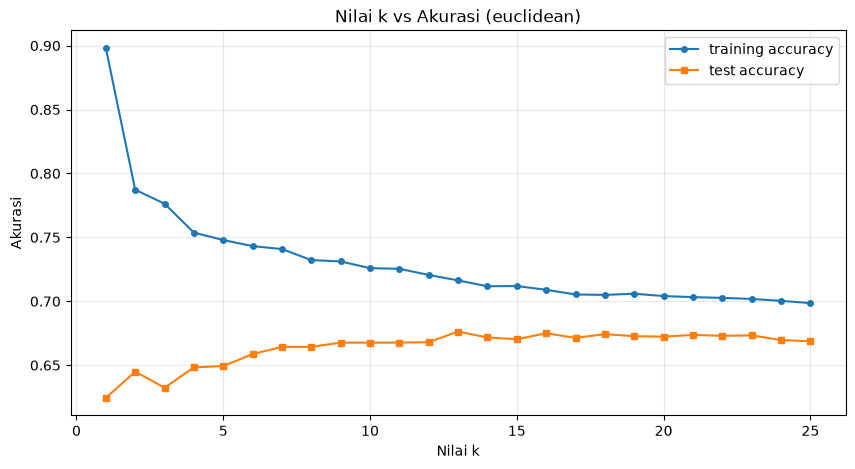

k terbaik: 13 dengan akurasi test 0.6763


In [3]:
k_range = range(1, 26)
train_acc = []
test_acc = []
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    train_acc.append(knn.score(X_train, y_train))
    test_acc.append(knn.score(X_test, y_test))

plt.figure(figsize=(10, 5))
plt.plot(k_range, train_acc, marker='o', markersize=4, label='training accuracy')
plt.plot(k_range, test_acc, marker='s', markersize=4, label='test accuracy')
plt.title('Nilai k vs Akurasi (euclidean)')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_k = int(np.argmax(test_acc)) + 1
print(f'k terbaik: {best_k} dengan akurasi test {test_acc[best_k-1]:.4f}')

## 4. Perbandingan Metrik Jarak (sesuai jobsheet)

Empat metrik jarak yang disebutkan di jobsheet diuji pada **k terbaik** dari langkah sebelumnya:

- **Euclidean** (umum digunakan; = Minkowski p=2)
- **Manhattan** (= Minkowski p=1)
- **Minkowski** (bentuk umum; di sini dipakai p=3 agar tidak duplikat euclidean/manhattan)
- **Cosine**

In [4]:
hasil_metrik = []
konfigurasi_metrik = [
    ('Euclidean (Minkowski p=2)', {'metric': 'minkowski', 'p': 2}),
    ('Manhattan (Minkowski p=1)', {'metric': 'manhattan'}),
    ('Minkowski (p=3)', {'metric': 'minkowski', 'p': 3}),
    ('Cosine', {'metric': 'cosine'}),
]

for nama, params in konfigurasi_metrik:
    knn = KNeighborsClassifier(n_neighbors=best_k, **params)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    hasil_metrik.append({
        'Metrik': nama,
        'Akurasi': accuracy_score(y_test, y_pred),
        'Precision (macro)': precision_score(y_test, y_pred, average='macro'),
        'Recall (macro)': recall_score(y_test, y_pred, average='macro'),
        'F1 (macro)': f1_score(y_test, y_pred, average='macro'),
    })

tabel_metrik = pd.DataFrame(hasil_metrik).round(4)
tabel_metrik

,Metrik,Akurasi,Precision (macro),Recall (macro),F1 (macro)
0,Euclidean (Minkowski p=2),0.6763,0.6679,0.6767,0.6699
1,Manhattan (Minkowski p=1),0.6760,0.6677,0.6764,0.6698
2,Minkowski (p=3),0.6743,0.6658,0.6747,0.6679
3,Cosine,0.6710,0.6627,0.6714,0.6650


## 5. Model Final kNN (konfigurasi terbaik)

In [5]:
# Pilih konfigurasi terbaik berdasarkan F1 macro
best_idx = int(np.argmax([r['F1 (macro)'] for r in hasil_metrik]))
best_nama, best_params = konfigurasi_metrik[best_idx]
print(f'Konfigurasi terbaik: k={best_k}, metric={best_nama}')

knn_final = KNeighborsClassifier(n_neighbors=best_k, **best_params)
knn_final.fit(X_train, y_train)
y_pred_final = knn_final.predict(X_test)

print(f"\nAkurasi  : {accuracy_score(y_test, y_pred_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_final, average='macro'):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_final, average='macro'):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_final, average='macro'):.4f}")
print()
print(classification_report(y_test, y_pred_final))

Konfigurasi terbaik: k=13, metric=Euclidean (Minkowski p=2)

Akurasi  : 0.6763


Precision: 0.6679
Recall   : 0.6767
F1-score : 0.6699

              precision    recall  f1-score   support

       Mahal       0.73      0.79      0.76      1000
       Murah       0.71      0.77      0.74       996
      Sedang       0.57      0.47      0.51      1004

    accuracy                           0.68      3000
   macro avg       0.67      0.68      0.67      3000
weighted avg       0.67      0.68      0.67      3000



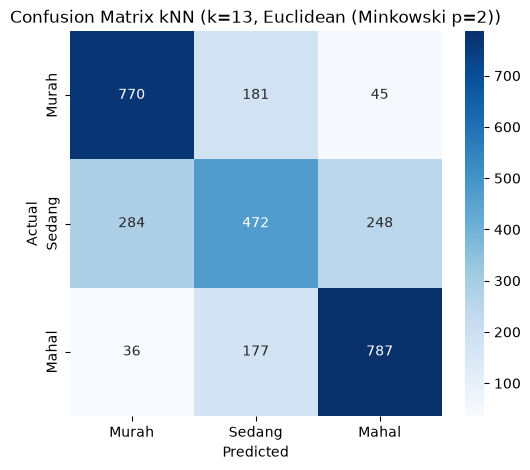

In [6]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred_final, labels=['Murah', 'Sedang', 'Mahal'])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Murah', 'Sedang', 'Mahal'],
            yticklabels=['Murah', 'Sedang', 'Mahal'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix kNN (k={best_k}, {best_nama})')
plt.show()

## 6. Simpan Hasil (untuk notebook Perbandingan)

In [7]:
hasil_knn = {
    'Metode': 'kNN',
    'Konfigurasi': f'k={best_k}, metric={best_nama}',
    'Akurasi': accuracy_score(y_test, y_pred_final),
    'Precision': precision_score(y_test, y_pred_final, average='macro'),
    'Recall': recall_score(y_test, y_pred_final, average='macro'),
    'F1': f1_score(y_test, y_pred_final, average='macro'),
}
pd.DataFrame([hasil_knn]).to_csv('hasil_knn.csv', index=False)
print('Tersimpan: hasil_knn.csv')
pd.DataFrame([hasil_knn]).round(4)

Tersimpan: hasil_knn.csv


,Metode,Konfigurasi,Akurasi,Precision,Recall,F1
0,kNN,"k=13, metric=Euclidean (Minkowski p=2)",0.6763,0.6679,0.6767,0.6699


## 7. Analisis kNN

**(a) Tuning nilai k:** Dari evaluasi k=1–25 (metrik euclidean), diperoleh **k=13** sebagai nilai terbaik dengan akurasi test **0.6763**. Pada k kecil akurasi training sangat tinggi tetapi test lebih rendah (overfitting — model menghafal tetangga terdekat); pada k besar akurasi test menurun kembali (underfitting — keputusan terlalu dirata-rata). k=13 adalah titik seimbangnya.

**(b) Perbandingan metrik jarak (pada k=13):**

| Metrik | Akurasi | F1 (macro) |
|---|---|---|
| **Euclidean (Minkowski p=2)** | **0.6763** | **0.6699** |
| Manhattan (Minkowski p=1) | 0.6760 | 0.6698 |
| Minkowski (p=3) | 0.6743 | 0.6679 |
| Cosine | 0.6710 | 0.6650 |

Keempat metrik menghasilkan performa yang **sangat berdekatan** (selisih akurasi < 0,6%). **Euclidean** sedikit terbaik — konsisten dengan keterangan jobsheet bahwa euclidean "umum digunakan". Cosine paling rendah karena mengukur sudut antar vektor (bukan jarak absolut), kurang cocok untuk fitur properti yang skala besarannya bermakna langsung. Minkowski memang bentuk umum (p=1 = manhattan, p=2 = euclidean); p=3 memberi penalti lebih besar pada perbedaan besar dan hasilnya berada di antaranya.

**(c) Performa per kelas:** kelas **Mahal** (F1=0.76) dan **Murah** (F1=0.74) lebih mudah dikenali, sedangkan **Sedang** paling sulit (F1=0.51, recall hanya 0.47) — wajar karena kelas tengah berbatasan langsung dengan kedua kelas lain di ruang fitur, sehingga banyak yang salah ke Murah/Mahal.

**(d) Kesimpulan:** model final **kNN k=13, euclidean** mencapai akurasi **0.6763** — cukup baik untuk baseline, namun kelas Sedang tetap menjadi tantangan.